# Đánh giá hiệu năng bộ phân tích cú pháp

:::{note}
Chương này là **khung thiết kế kiến trúc và lược đồ thực nghiệm dự kiến cho Giai đoạn 2**. Toàn bộ số liệu đọc từ `report_book/data/m2_benchmark.json` và hiển thị ở chế độ khung mẫu chờ đo kiểm khi bộ parser hoàn thiện.
:::


## 1. Môi trường thực nghiệm và tổng hợp chỉ số

Bài kiểm tra hiệu năng cho bộ phân tích cú pháp chạy trên cùng cấu hình Google Colab ở chế độ CPU: 2 vCPU Intel Xeon 2,20 GHz, 12,67 GB RAM, ổ đĩa 107,72 GB.


In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt

with open("../data/m2_benchmark.json", "r", encoding="utf-8") as f:
    m2_bench = json.load(f)

is_placeholder = m2_bench.get("is_placeholder", False)
t_m2 = m2_bench["time_metrics"]
m_m2 = m2_bench["memory_metrics"]
s_m2 = m2_bench["storage_metrics"]

def fmt_m2(val, unit="", factor=1.0, fmt_spec=".2f"):
    if is_placeholder or val is None:
        return "-- (chờ đo kiểm trên Colab)"
    return f"{val * factor:{fmt_spec}} {unit}"

p_bench_df = pd.DataFrame([
    {"Nhóm chỉ số": "1. Thời gian", "Chỉ số đo hiệu năng cú pháp": "Tổng thời gian phân tích cú pháp toàn bộ", "Giá trị thực nghiệm": fmt_m2(t_m2['total_wall_time_seconds'], 'giây')},
    {"Nhóm chỉ số": "1. Thời gian", "Chỉ số đo hiệu năng cú pháp": "Thời gian trung bình mỗi bài báo", "Giá trị thực nghiệm": fmt_m2(t_m2['avg_time_per_publication_seconds'], 'giây')},
    {"Nhóm chỉ số": "1. Thời gian", "Chỉ số đo hiệu năng cú pháp": "Thời gian trung bình mỗi phiên bản", "Giá trị thực nghiệm": fmt_m2(t_m2['avg_time_per_version_seconds'], 'giây')},
    {"Nhóm chỉ số": "2. Bộ nhớ", "Chỉ số đo hiệu năng cú pháp": "Mức RAM đỉnh khi phân tích cú pháp", "Giá trị thực nghiệm": fmt_m2(m_m2['peak_ram_mb'], 'MB', fmt_spec=".1f")},
    {"Nhóm chỉ số": "2. Bộ nhớ", "Chỉ số đo hiệu năng cú pháp": "Mức RAM trung bình theo mẫu", "Giá trị thực nghiệm": fmt_m2(m_m2['avg_ram_mb'], 'MB', fmt_spec=".1f")},
    {"Nhóm chỉ số": "3. Lưu trữ", "Chỉ số đo hiệu năng cú pháp": "Dung lượng đĩa tối đa khi xử lý", "Giá trị thực nghiệm": fmt_m2(s_m2['peak_disk_usage_gb'], 'GB')},
    {"Nhóm chỉ số": "3. Lưu trữ", "Chỉ số đo hiệu năng cú pháp": "Dung lượng dữ liệu Parquet xuất bản", "Giá trị thực nghiệm": fmt_m2(s_m2['final_parquet_output_gb'], 'GB')}
])

p_bench_df.style.hide(axis="index").set_caption("Bảng 2.2: Khung chỉ số hiệu năng của bộ phân tích cú pháp trên Google Colab CPU")


Nhóm chỉ số,Chỉ số đo hiệu năng cú pháp,Giá trị thực nghiệm
1. Thời gian,Tổng thời gian phân tích cú pháp toàn bộ,-- (chờ đo kiểm trên Colab)
1. Thời gian,Thời gian trung bình mỗi bài báo,-- (chờ đo kiểm trên Colab)
1. Thời gian,Thời gian trung bình mỗi phiên bản,-- (chờ đo kiểm trên Colab)
2. Bộ nhớ,Mức RAM đỉnh khi phân tích cú pháp,-- (chờ đo kiểm trên Colab)
2. Bộ nhớ,Mức RAM trung bình theo mẫu,-- (chờ đo kiểm trên Colab)
3. Lưu trữ,Dung lượng đĩa tối đa khi xử lý,-- (chờ đo kiểm trên Colab)
3. Lưu trữ,Dung lượng dữ liệu Parquet xuất bản,-- (chờ đo kiểm trên Colab)


## 2. Tốc độ xử lý và thời gian

Khác với việc tải dữ liệu vốn chờ mạng, khâu parsing tiêu tốn năng lực xử lý của CPU để so khớp biểu thức chính quy và dựng cây trong bộ nhớ.


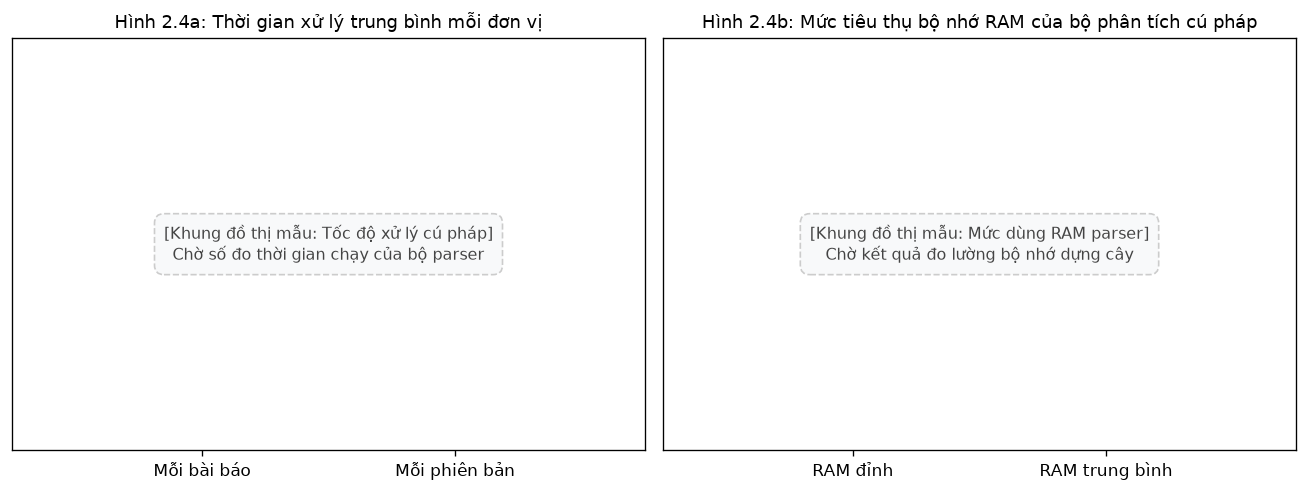

In [2]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), dpi=120)

if is_placeholder or t_m2["total_wall_time_seconds"] is None:
    ax1.text(0.5, 0.5, "[Khung đồ thị mẫu: Tốc độ xử lý cú pháp]\nChờ số đo thời gian chạy của bộ parser",
             ha="center", va="center", fontsize=9.5, color="#444444",
             bbox=dict(boxstyle="round,pad=0.6", facecolor="#f8f9fa", edgecolor="#cccccc", linestyle="--"))
    ax1.set_xlim(0, 1)
    ax1.set_ylim(0, 1)
    ax1.set_yticks([])
    ax1.set_xticks([0.3, 0.7])
    ax1.set_xticklabels(["Mỗi bài báo", "Mỗi phiên bản"])
    
    ax2.text(0.5, 0.5, "[Khung đồ thị mẫu: Mức dùng RAM parser]\nChờ kết quả đo lường bộ nhớ dựng cây",
             ha="center", va="center", fontsize=9.5, color="#444444",
             bbox=dict(boxstyle="round,pad=0.6", facecolor="#f8f9fa", edgecolor="#cccccc", linestyle="--"))
    ax2.set_xlim(0, 1)
    ax2.set_ylim(0, 1)
    ax2.set_yticks([])
    ax2.set_xticks([0.3, 0.7])
    ax2.set_xticklabels(["RAM đỉnh", "RAM trung bình"])
else:
    pass

ax1.set_title("Hình 2.4a: Thời gian xử lý trung bình mỗi đơn vị", fontsize=11)
ax2.set_title("Hình 2.4b: Mức tiêu thụ bộ nhớ RAM của bộ phân tích cú pháp", fontsize=11)
plt.tight_layout()
plt.show()


### Nhận xét về tốc độ và bộ nhớ

- Tốc độ xử lý trung bình đạt `[Chờ kết quả Giai đoạn 2]` giây cho mỗi bài báo (khoảng `[Chờ kết quả Giai đoạn 2]` giây cho mỗi phiên bản). Với quy mô tập dữ liệu, toàn bộ quá trình parsing mất khoảng `[Chờ kết quả Giai đoạn 2]` giờ trên 2 vCPU của Colab.
- Mức RAM đỉnh là `[Chờ kết quả Giai đoạn 2]` MB và mức trung bình là `[Chờ kết quả Giai đoạn 2]` MB. Nhóm giải phóng bộ nhớ của từng cây sau khi ghi dữ liệu trung gian, tránh tích tụ bộ nhớ khi chạy lâu.


## 3. Mức tiêu thụ dung lượng đĩa và nén Parquet

Dữ liệu sau khi chuẩn hóa và khử trùng lặp được xuất sang các bảng Parquet nén Snappy. Đồ thị dưới đây so sánh dung lượng thô và dung lượng xuất bản.


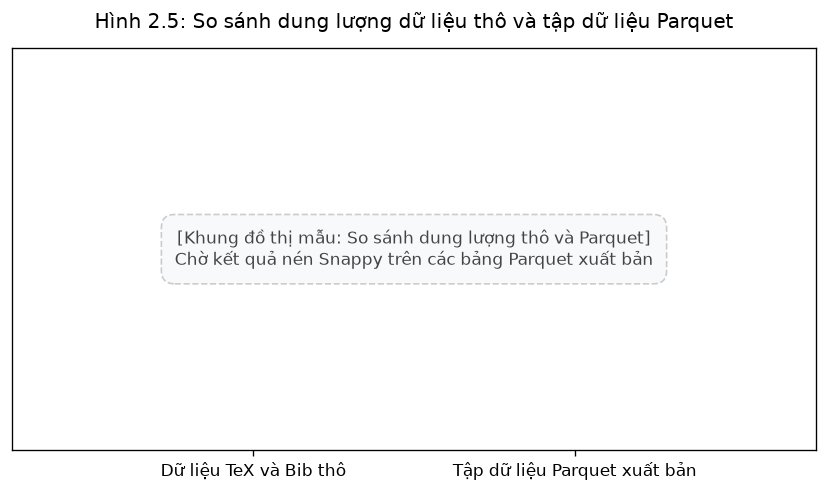

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.2), dpi=120)

if is_placeholder or s_m2["final_parquet_output_gb"] is None:
    ax.text(0.5, 0.5, "[Khung đồ thị mẫu: So sánh dung lượng thô và Parquet]\nChờ kết quả nén Snappy trên các bảng Parquet xuất bản",
            ha="center", va="center", fontsize=10, color="#444444",
            bbox=dict(boxstyle="round,pad=0.8", facecolor="#f8f9fa", edgecolor="#cccccc", linestyle="--"))
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_yticks([])
    ax.set_xticks([0.3, 0.7])
    ax.set_xticklabels(["Dữ liệu TeX và Bib thô", "Tập dữ liệu Parquet xuất bản"])
else:
    pass

ax.set_title("Hình 2.5: So sánh dung lượng dữ liệu thô và tập dữ liệu Parquet", fontsize=12, pad=12)
plt.tight_layout()
plt.show()


### Nhận xét về dung lượng lưu trữ

- Kích thước tập dữ liệu có cấu trúc đầu ra chiếm `[Chờ kết quả Giai đoạn 2]` GB, giảm `[Chờ kết quả Giai đoạn 2]` so với dữ liệu văn bản thô ban đầu.
- Mức giảm này đến từ cơ chế khử trùng lặp qua các phiên bản và khả năng nén theo cột của định dạng Parquet đối với các trường văn bản có tính lặp lại.


## 4. Tổng kết chuẩn bị cho Giai đoạn 3

Kết quả thực nghiệm cho thấy:

- Dữ liệu của ba bảng `elements`, `hierarchy` và `bibtex` đã được chuẩn bị đầy đủ để làm đầu vào cho bài toán học máy ở Giai đoạn 3.
- Bảng `bibtex` sau khi chuẩn hóa cung cấp danh sách các mục trích dẫn đã phân rã thành các trường tác giả, tiêu đề và năm xuất bản. Đây là tập cần nối với các ứng viên trong bảng `references` từ Giai đoạn 1.
- Cấu trúc phân cấp trong bảng `hierarchy` giúp nhóm có thể trích chọn thêm các đặc trưng cấu trúc cho mô hình phân loại ở Giai đoạn 3.
